# Lab 2 - Zadanie

In [1]:
!pip install torch torchvision matplotlib

In [2]:
import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | urządzenie: cuda


In [3]:
mean, std = 0.2860, 0.3530
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])
tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(28, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

full_ds = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True, transform=tf)
full_aug_ds = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True, transform=tf_aug)
test_ds = torchvision.datasets.FashionMNIST(
    "./data", train=False, download=True, transform=tf)
classes = test_ds.classes

split_gen = torch.Generator().manual_seed(42)
perm = torch.randperm(len(full_ds), generator=split_gen)
train_idx, val_idx = perm[:50000].tolist(), perm[50000:].tolist()

train_ds = Subset(full_ds, train_idx)
train_aug_ds = Subset(full_aug_ds, train_idx)
val_ds = Subset(full_ds, val_idx)

train_eval_dl = DataLoader(train_ds, batch_size=256, shuffle=False)
val_dl = DataLoader(val_ds, batch_size=256, shuffle=False)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False)
print("Trening:", len(train_ds), "| Walidacja:", len(val_ds),
      "| Test:", len(test_ds))

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 320kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.63MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.0MB/s]


Trening: 50000 | Walidacja: 10000 | Test: 10000


## 1. Model

In [4]:
class MLP(nn.Module):
    def __init__(self, in_dim=28 * 28, hidden=(256, 128), n_classes=10,
                 use_bn=False, p_drop=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

## 2. Trenowanie i ocena

In [5]:
EPOCHS = 12


def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum / total, correct / total


def train_model(cfg, epochs=EPOCHS, lr=1e-3):
    torch.manual_seed(0)
    model = MLP(use_bn=cfg["bn"], p_drop=cfg["dropout"]).to(device)
    train_dl = DataLoader(train_aug_ds if cfg["aug"] else train_ds,
                          batch_size=128, shuffle=True)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr,
                                 weight_decay=cfg["wd"])
    scheduler = None
    if cfg["sched"]:
        scheduler = torch.optim.lr_scheduler.StepLR(
            optimizer, step_size=epochs // 3, gamma=0.5)
    hist = {"train_loss": [], "train_eval_loss": [],
            "val_loss": [], "val_acc": []}
    best_loss, best_state = float("inf"), None
    for _ in range(epochs):
        model.train()
        run_loss = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * yb.numel()
        if scheduler is not None:
            scheduler.step()
        train_eval_loss, _ = evaluate(model, train_eval_dl)
        val_loss, val_acc = evaluate(model, val_dl)
        hist["train_loss"].append(run_loss / len(train_ds))
        hist["train_eval_loss"].append(train_eval_loss)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, hist

## 3. Baseline i pojedyncze ulepszenia

In [6]:
base_cfg = {"bn": False, "dropout": 0.0, "wd": 0.0,
            "aug": False, "sched": False}
changes = {
    "BatchNorm": {"bn": True},
    "dropout 0.3": {"dropout": 0.3},
    "weight decay 1e-4": {"wd": 1e-4},
    "augmentacja": {"aug": True},
    "scheduler StepLR": {"sched": True},
}
results = {}


def run(name, cfg):
    model, hist = train_model(cfg)
    best = min(range(EPOCHS), key=lambda e: hist["val_loss"][e])
    results[name] = {"model": model, "hist": hist, "best": best}


run("baseline", base_cfg)
for name, change in changes.items():
    run(name, {**base_cfg, **change})

## 4. Kombinacja ulepszeń

In [7]:
base_loss = min(results["baseline"]["hist"]["val_loss"])
helped = [name for name in changes
          if min(results[name]["hist"]["val_loss"]) < base_loss]
if len(helped) > 1:
    combo_cfg = dict(base_cfg)
    for name in helped:
        combo_cfg.update(changes[name])
    run(" + ".join(helped), combo_cfg)

## 5. Wyniki na zbiorze walidacyjnym

In [8]:
rows = []
for name, r in results.items():
    h, e = r["hist"], r["best"]
    rows.append({
        "konfiguracja": name,
        "wybrana epoka": e + 1,
        "val_loss": h["val_loss"][e],
        "accuracy walidacyjna [%]": h["val_acc"][e] * 100,
        "luka train-val": h["val_loss"][e] - h["train_eval_loss"][e],
    })
table = pd.DataFrame(rows)
best_name = table.loc[table["val_loss"].idxmin(), "konfiguracja"]
print("Wybrana konfiguracja:", best_name)
table.round({"val_loss": 4, "accuracy walidacyjna [%]": 2,
             "luka train-val": 4})

Wybrana konfiguracja: scheduler StepLR


,konfiguracja,wybrana epoka,val_loss,accuracy walidacyjna [%],luka train-val
0,baseline,6,0.3089,89.19,0.0872
1,BatchNorm,4,0.3091,88.76,0.0766
2,dropout 0.3,10,0.3061,89.10,0.0763
3,weight decay 1e-4,6,0.3118,88.81,0.0810
4,augmentacja,12,0.4352,84.10,0.0137
5,scheduler StepLR,9,0.2833,90.01,0.1124
6,dropout 0.3 + scheduler StepLR,11,0.2936,89.45,0.0795


## 6. Krzywe uczenia

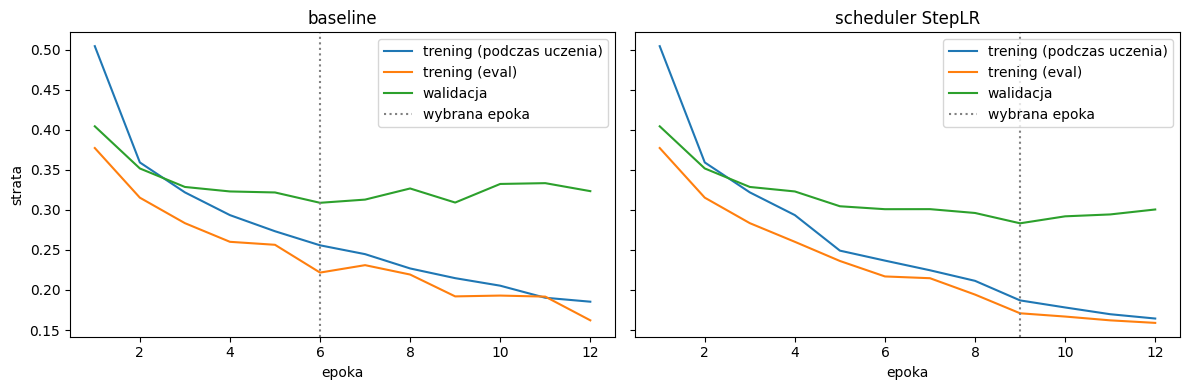

In [9]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ["baseline", best_name]):
    h, e = results[name]["hist"], results[name]["best"]
    ax.plot(epochs, h["train_loss"], label="trening (podczas uczenia)")
    ax.plot(epochs, h["train_eval_loss"], label="trening (eval)")
    ax.plot(epochs, h["val_loss"], label="walidacja")
    ax.axvline(e + 1, color="gray", linestyle=":", label="wybrana epoka")
    ax.set_title(name)
    ax.set_xlabel("epoka")
    ax.legend()
axes[0].set_ylabel("strata")
plt.tight_layout()
plt.show()

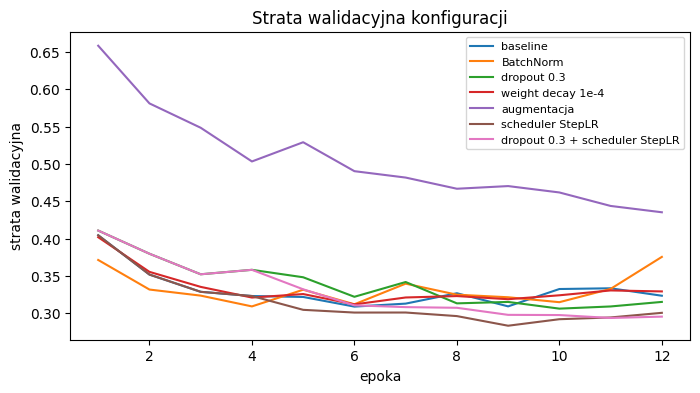

In [10]:
plt.figure(figsize=(8, 4))
for name, r in results.items():
    plt.plot(epochs, r["hist"]["val_loss"], label=name)
plt.xlabel("epoka")
plt.ylabel("strata walidacyjna")
plt.title("Strata walidacyjna konfiguracji")
plt.legend(fontsize=8)
plt.show()

## 7. Ocena końcowa na zbiorze testowym

In [11]:
test_rows = []
for name in dict.fromkeys(["baseline", best_name]):
    _, test_acc = evaluate(results[name]["model"], test_dl)
    test_rows.append({"model": name,
                      "accuracy testowa [%]": round(test_acc * 100, 2)})
pd.DataFrame(test_rows)

,model,accuracy testowa [%]
0,baseline,88.45
1,scheduler StepLR,89.60
